Here I shall train and evaluate my model's performance 

Import necessary functions and libraries first

In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from src.data_preprocessing import preprocess_titanic_data
from src.NN_model import BinaryClassifierNN, train_and_validate

Now I import training data and clean it

In [2]:
raw_train_data = pd.read_csv('~/Desktop/Titanic_Survival/data/Titanic_train.csv')
noise = raw_train_data['Survived'].isna() | (raw_train_data['Survived'] == '')

# Get the matching rows
missing_rows = raw_train_data[noise]
print(missing_rows)

train_data_cleaned = raw_train_data[~noise]

# I split a portion of the data for validation
train_data_cleaned, valid_data_cleaned = train_test_split(train_data_cleaned, test_size=0.2, random_state=42)

print(len(train_data_cleaned), len(valid_data_cleaned)) 
#print(train_data_cleaned.columns,valid_data_cleaned.columns)

Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []
712 179


In [3]:
train_data_cleaned_copied = train_data_cleaned.copy() 
print(len(train_data_cleaned_copied))

712


Keep a separate copy of targets for both training and validation datasets and also drop the "Survived" columns from both before creating trainable features out of them

In [4]:
train_target = train_data_cleaned_copied[['Survived']].astype(np.float32)
valid_target = valid_data_cleaned[['Survived']].astype(np.float32)

Final_train_data = train_data_cleaned_copied.drop(columns=['Survived'])
Final_valid_data = valid_data_cleaned.drop(columns=['Survived'])

Now I shall use "preprocess_titanic_data" to create trainable feature dataframes

In [5]:
train_data_processed, scaler_A_train, scaler_ticket_train = preprocess_titanic_data(Final_train_data)
# This is to ensure a specific order of the feature columns to maintain consistency
train_cols = [col for col in train_data_processed.columns if col != 'Survived']
train_data_processed = train_data_processed[train_cols]

# Now for validation dataset
valid_data_processed, _, _ = preprocess_titanic_data(Final_valid_data, scaler_A=scaler_A_train, scaler_ticket=scaler_ticket_train, reference_columns=train_cols)
valid_data_processed = valid_data_processed.reindex(columns=train_cols, fill_value=0).astype(np.float32) 
# reindexing is needed because some features appears in training dataset but not in validation dataset

print(train_data_processed.shape[1],valid_data_processed.shape[1])
print(len(train_data_processed), len(valid_data_processed), len(train_target), len(valid_target))

45 45
712 179 712 179


Now our training and validation datasets are prepared and hence we can go for model training and validation

## Model training and validation

In [6]:
X_train = torch.tensor(train_data_processed.to_numpy()) 
Y_train = torch.tensor(train_target.to_numpy())
training_data = DataLoader(TensorDataset(X_train,Y_train), batch_size = 16, shuffle=True)
################################################################################################
X_valid = torch.tensor(valid_data_processed.to_numpy()) 
Y_valid = torch.tensor(valid_target.to_numpy())
validation_data = DataLoader(TensorDataset(X_valid,Y_valid), batch_size = 16, shuffle=True)

Now we are all ready for training and validation of my model

In [7]:
model = BinaryClassifierNN(input_size=X_train.shape[1])
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
model = model.to(device)          # move before building the optimizer 

train_valid_output = train_and_validate(
    training_dataset=training_data,
    validation_dataset=validation_data,
    Mymodel=model,
    loss_fn=nn.BCEWithLogitsLoss(),
    optimizer=torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-2),
    epochs=20,device = device,)

In [8]:
print(train_valid_output)

{'epochs': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20], 'train_loss': [0.6719229896863301, 0.6304932753245036, 0.5804967270957099, 0.5209008759922451, 0.4929604904519187, 0.4882575015227, 0.46438458296987745, 0.45807185769081116, 0.4464515659544203, 0.4234305722845925, 0.4299668010738161, 0.4225317913624975, 0.42449036803510454, 0.41860589053895736, 0.39609402070442834, 0.4046401795413759, 0.4002108613650004, 0.40645908067623776, 0.39585913750860424, 0.408804722627004], 'valid_loss': [0.6555866549412409, 0.6007835467656454, 0.5278316959738731, 0.5042884026964506, 0.46028317759434384, 0.45790285244584084, 0.4667761226495107, 0.44846727947394055, 0.41653091336290043, 0.4155261032283306, 0.4425489877661069, 0.4220220148563385, 0.4113834525148074, 0.42544052625695866, 0.4419708400964737, 0.4350851699709892, 0.4134021537999312, 0.4579317905008793, 0.4262949575980504, 0.43309163053830463], 'accuracy': [68.15642458100558, 70.39106145251397, 75.41899441340783, 74.86

## Checking model performance

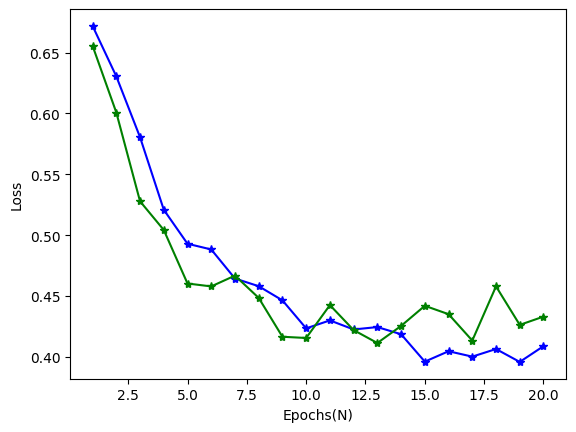

In [9]:
plt.plot(train_valid_output["epochs"],train_valid_output["train_loss"],'b-', marker='*')
plt.plot(train_valid_output["epochs"],train_valid_output["valid_loss"],'g-', marker='*')

plt.xlabel('Epochs(N)')
plt.ylabel('Loss')

plt.show()

Even after 20 epochs training loss is ~0.40 and validation loss is ~0.43 which shows no large overfitting. 

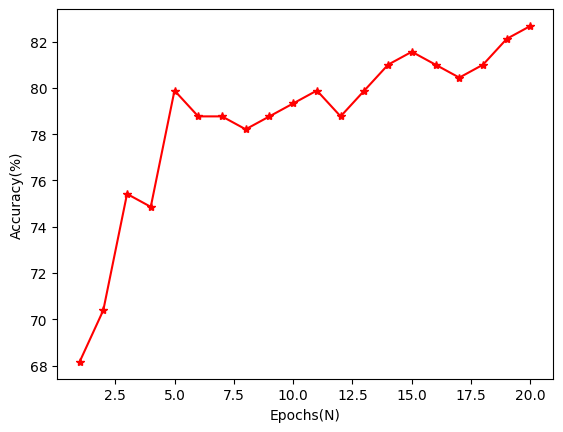

In [10]:
plt.plot(train_valid_output["epochs"],train_valid_output["accuracy"],'r-', marker='*')

plt.xlabel('Epochs(N)')
plt.ylabel('Accuracy(%)')

plt.show()

## Model Saving

Now we save the created model 

In [11]:
save_dir = os.path.expanduser('~/Desktop/Titanic_Survival/outputs')
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, 'model_weights.pth')
torch.save(model.state_dict(), save_path)

## Reloading model and test data to perform test run

First we load the testdata and do the processing

In [12]:
test_data = pd.read_csv('~/Desktop/Titanic_Survival/data/Titanic_test.csv')
test_data_processed, _, _ = preprocess_titanic_data(test_data,scaler_A=scaler_A_train,scaler_ticket=scaler_ticket_train,reference_columns=train_cols)
test_data_processed = test_data_processed.reindex(columns=train_cols, fill_value=0).astype(np.float32) 

Now we load the model

In [13]:
test_model = BinaryClassifierNN(input_size=test_data_processed.shape[1])
test_model.load_state_dict(torch.load(save_path, weights_only=True))

<All keys matched successfully>

Now we do the testing

In [14]:
X_test_tensor = torch.tensor(test_data_processed.values, dtype=torch.float32)

test_model.eval()

device = next(test_model.parameters()).device
X_test_tensor = X_test_tensor.to(device)

with torch.no_grad():
    raw_outputs = test_model(X_test_tensor)
    
    probabilities = torch.sigmoid(raw_outputs)
    
survival_probs = probabilities.cpu().numpy().flatten()

predictions = (survival_probs >= 0.5).astype(int)

Now we save our prediction as a dataframe and save it as a .csv file

In [15]:
test_data_prediction = test_data.copy()
test_data_prediction['Survived'] = predictions
test_data_prediction.to_csv('~/Desktop/Titanic_Survival/outputs/Titanic_survival_predictions.csv', index=False)